# Задача 1. Tree Traversal

**Объяснение решения**

Каждый узел хранит значение `value` и ссылки `left` и `right`.
В левом поддереве находятся значения меньше текущего, в правом - больше
или равные. Повторы сохраняются.

При **вставке** метод `insert` вызывает `_insert` для корня дерева.
Базовый случай - `node is None`: на свободном месте создаётся новый узел.
Если значение меньше текущего, рекурсивно вставляем его в левое поддерево,
иначе - в правое. `_insert` возвращает корень обновлённого поддерева,
и мы записываем его в соответствующую ссылку. Так новый узел правильно
присоединяется к дереву, включая случай вставки первого элемента.

Для **обходов** метод `_traverse` создаёт список `result` и запускает
рекурсивную функцию `visit`. Её базовый случай — пустое поддерево:
если `node is None`, вызов сразу завершается. Для существующего узла
выполняем три действия в порядке, заданном строкой `order`:
`N` — добавить значение в результат, `L` — вызвать `visit(node.left)`,
`R` — вызвать `visit(node.right)`.

| Обход | Порядок действий |
|---|---|
| `preorder` | NLR: узел → левое → правое |
| `inorder` | LNR: левое → узел → правое |
| `postorder` | LRN: левое → правое → узел |
| `reverse_preorder` | NRL: узел → правое → левое |
| `reverse_inorder` | RNL: правое → узел → левое |
| `reverse_postorder` | RLN: правое → левое → узел |

Рекурсивный вызов полностью обрабатывает своё поддерево, затем возвращает
управление родительскому вызову. Например, `inorder` сначала записывает
все значения левого поддерева, затем значение узла и затем значения
правого поддерева. Благодаря свойству BST результат оказывается
отсортирован по неубыванию.

Каждый узел добавляется ровно один раз. Все вызовы одного обхода используют
общий список и добавляют значения через `append`, поэтому обход занимает
`O(n)` времени. Для каждого нового обхода создаётся отдельный список.

**Решение**

In [1]:
from __future__ import annotations

from dataclasses import dataclass
from typing import Iterable


@dataclass
class Node:
    value: int
    left: Node | None = None
    right: Node | None = None


class BST:
    """BST: слева значения < value, справа значения >= value."""

    def __init__(self, values: Iterable[int] = ()) -> None:
        self.root: Node | None = None
        for value in values:
            self.insert(value)

    def insert(self, value: int) -> None:
        self.root = self._insert(self.root, value)

    def _insert(self, node: Node | None, value: int) -> Node:
        if node is None:
            return Node(value)

        if value < node.value:
            node.left = self._insert(node.left, value)
        else:
            # Равные значения тоже направляем вправо.
            node.right = self._insert(node.right, value)

        return node

    def _traverse(self, order: str) -> list[int]:
        result: list[int] = []

        def visit(node: Node | None) -> None:
            if node is None:
                return

            for action in order:
                if action == "N":
                    result.append(node.value)
                elif action == "L":
                    visit(node.left)
                elif action == "R":
                    visit(node.right)

        visit(self.root)
        return result

    def preorder(self) -> list[int]:
        return self._traverse("NLR")

    def inorder(self) -> list[int]:
        return self._traverse("LNR")

    def postorder(self) -> list[int]:
        return self._traverse("LRN")

    def reverse_preorder(self) -> list[int]:
        return self._traverse("NRL")

    def reverse_inorder(self) -> list[int]:
        return self._traverse("RNL")

    def reverse_postorder(self) -> list[int]:
        return self._traverse("RLN")

**Пример**

Последовательно вставим значения
`[8, 3, 10, 1, 6, 14, 4, 7, 13]`.

Последнее значение `13` вставляется так:

| Шаг | Сравнение | Действие |
|---|---|---|
| 1 | `13 > 8` | Перейти вправо к `10` |
| 2 | `13 > 10` | Перейти вправо к `14` |
| 3 | `13 < 14` | Проверить левую ссылку |
| 4 | Левая ссылка свободна | Создать узел `13` слева от `14` |

Следующая ячейка рисует дерево по его реальным узлам. Метки `L` и `R`
показывают направление каждой связи. Эту ячейку я загптшила, чтобы не рисовать руками)

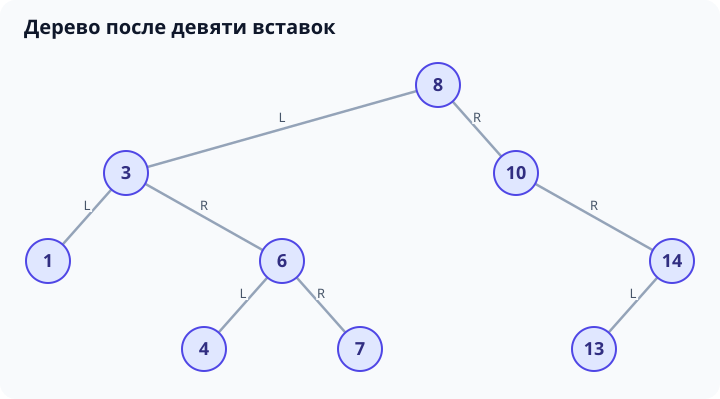

In [2]:
from html import escape
from IPython.display import HTML, Markdown, SVG, display


def tree_svg(tree, title="Бинарное дерево поиска"):
    """SVG-схема небольшого дерева; расположение узлов задаёт inorder."""
    if tree.root is None:
        return (
            '<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 720 140">'
            '<rect width="720" height="140" rx="16" fill="#f8fafc"/>'
            f'<text x="24" y="36" font-family="sans-serif" font-size="20" '
            f'fill="#0f172a">{escape(title)}</text>'
            '<text x="360" y="95" text-anchor="middle" font-family="sans-serif" '
            'font-size="18" fill="#475569">Пустое дерево: root = None</text></svg>'
        )

    ordered = []

    def collect(node, depth):
        if node is None:
            return
        collect(node.left, depth + 1)
        ordered.append((node, depth))
        collect(node.right, depth + 1)

    collect(tree.root, 0)

    width, margin, level_gap, radius = 720, 48, 88, 22
    height = 135 + level_gap * max(depth for _, depth in ordered)
    positions = {}
    for index, (node, depth) in enumerate(ordered):
        x = width / 2 if len(ordered) == 1 else (
            margin + index * (width - 2 * margin) / (len(ordered) - 1)
        )
        positions[id(node)] = (x, 85 + level_gap * depth)

    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" '
        f'width="{width}" role="img" aria-label="{escape(title, quote=True)}">',
        f'<rect width="{width}" height="{height}" rx="16" fill="#f8fafc"/>',
        f'<text x="24" y="34" font-family="sans-serif" font-size="20" '
        f'font-weight="600" fill="#0f172a">{escape(title)}</text>',
    ]
    for node, _ in ordered:
        x1, y1 = positions[id(node)]
        for child, label in ((node.left, "L"), (node.right, "R")):
            if child is None:
                continue
            x2, y2 = positions[id(child)]
            parts.append(
                f'<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" '
                'stroke="#94a3b8" stroke-width="2.5"/>'
            )
            parts.append(
                f'<text x="{(x1 + x2) / 2}" y="{(y1 + y2) / 2 - 7}" '
                'text-anchor="middle" font-family="sans-serif" font-size="13" '
                'fill="#475569" stroke="#f8fafc" stroke-width="4" '
                f'paint-order="stroke">{label}</text>'
            )
    for node, _ in ordered:
        x, y = positions[id(node)]
        parts.extend([
            f'<circle cx="{x}" cy="{y}" r="{radius}" fill="#e0e7ff" '
            'stroke="#4f46e5" stroke-width="2"/>',
            f'<text x="{x}" y="{y + 6}" text-anchor="middle" '
            'font-family="sans-serif" font-size="18" font-weight="600" '
            f'fill="#312e81">{node.value}</text>',
        ])
    parts.append('</svg>')
    return ''.join(parts)


values = [8, 3, 10, 1, 6, 14, 4, 7, 13]
tree = BST(values)
display(SVG(tree_svg(tree, "Дерево после девяти вставок")))

In [3]:
traversal_orders = {
    "preorder": "NLR",
    "inorder": "LNR",
    "postorder": "LRN",
    "reverse_preorder": "NRL",
    "reverse_inorder": "RNL",
    "reverse_postorder": "RLN",
}
rows = ["| Обход | Порядок | Результат |", "|---|---|---|"]
for name, order in traversal_orders.items():
    result = getattr(tree, name)()
    rows.append(f"| `{name}` | {order} | `{result}` |")
display(Markdown("\n".join(rows)))

| Обход | Порядок | Результат |
|---|---|---|
| `preorder` | NLR | `[8, 3, 1, 6, 4, 7, 10, 14, 13]` |
| `inorder` | LNR | `[1, 3, 4, 6, 7, 8, 10, 13, 14]` |
| `postorder` | LRN | `[1, 4, 7, 6, 3, 13, 14, 10, 8]` |
| `reverse_preorder` | NRL | `[8, 10, 14, 13, 3, 6, 7, 4, 1]` |
| `reverse_inorder` | RNL | `[14, 13, 10, 8, 7, 6, 4, 3, 1]` |
| `reverse_postorder` | RLN | `[13, 14, 10, 7, 4, 6, 1, 3, 8]` |

**Пошаговая работа рекурсивного `preorder`.** Начинаем с `visit(8)`.
Порядок `NLR` означает: записать значение, рекурсивно обойти левое
поддерево, затем правое. Вызов для `None` сразу возвращается.

Таблица показывает цепочку активных вызовов в момент записи очередного
значения. Справа находится текущий вызов. Например, после посещения `1`
выполняются два пустых вызова, затем управление возвращается к `3`,
и начинается обход его правого поддерева с корнем `6`.

| Шаг | Записан узел | Активные вызовы `visit` | Накопленный результат |
|---|---:|---|---|
| 1 | 8 | `8` | `[8]` |
| 2 | 3 | `8 → 3` | `[8, 3]` |
| 3 | 1 | `8 → 3 → 1` | `[8, 3, 1]` |
| 4 | 6 | `8 → 3 → 6` | `[8, 3, 1, 6]` |
| 5 | 4 | `8 → 3 → 6 → 4` | `[8, 3, 1, 6, 4]` |
| 6 | 7 | `8 → 3 → 6 → 7` | `[8, 3, 1, 6, 4, 7]` |
| 7 | 10 | `8 → 10` | `[8, 3, 1, 6, 4, 7, 10]` |
| 8 | 14 | `8 → 10 → 14` | `[8, 3, 1, 6, 4, 7, 10, 14]` |
| 9 | 13 | `8 → 10 → 14 → 13` | `[8, 3, 1, 6, 4, 7, 10, 14, 13]` |

После последнего значения оставшиеся вызовы завершаются, и `_traverse`
возвращает накопленный список.

**Сложность**

Пусть `n` — число узлов, а `h` — высота дерева (глубина). Сравнение целых чисел считаем операцией `O(1)`.

| Операция | Время | Память |
|---|---|---|
| Рекурсивная вставка в непустое дерево | `O(h)` | `O(h)` для стека вызовов |
| Вставка в пустое дерево | `O(1)` | `O(1)` |
| Каждый из шести рекурсивных обходов | `O(n)` | `O(h)` для вызовов + `O(n)` для результата |
| Построение дерева из `n` значений | `O(n²)` в худшем случае | `O(n)` для узлов + `O(h)` для вызовов |

Вставка проходит один путь. При сбалансированной форме `h = O(log n)`,
у цепочки `h = O(n)`. Вставки отсортированных значений требуют суммарно
`O(1 + 2 + … + n) = O(n²)` времени. Если дерево сохраняет сбалансированную
форму при построении, суммарное время составляет `O(n log n)`.
Эта реализация автоматически дерево не балансирует.

Обход выполняет постоянное количество действий для каждого узла.
Максимальное число одновременно активных вызовов пропорционально высоте
дерева. С учётом возвращаемого списка память обхода — **`O(n)`**.
Рисование схем и отображение таблиц в эти оценки алгоритмов не включены.

Python ограничивает глубину рекурсии. Если высота дерева превышает
доступную глубину вызовов, вставка или обход могут завершиться
`RecursionError`. В тесте цепочек из 2500 узлов лимит временно увеличивается
до 6000 или сохраняется более высокий исходный лимит; после теста исходное
значение восстанавливается.

**Тесты**

In [ ]:
import random
import sys
import unittest



METHODS = (
    "preorder", "inorder", "postorder",
    "reverse_preorder", "reverse_inorder", "reverse_postorder",
)


class TestBST(unittest.TestCase):
    def check_orders(self, values, expected):
        tree = BST(values)
        for name, answer in zip(METHODS, expected):
            with self.subTest(values=values, traversal=name):
                self.assertEqual(getattr(tree, name)(), answer)

    def test_empty(self):
        self.check_orders([], [[]] * 6)

    def test_single(self):
        self.check_orders([42], [[42]] * 6)

    def test_asymmetric(self):
        self.check_orders([8, 3, 10, 1, 6, 14, 4, 7, 13], [
            [8, 3, 1, 6, 4, 7, 10, 14, 13],
            [1, 3, 4, 6, 7, 8, 10, 13, 14],
            [1, 4, 7, 6, 3, 13, 14, 10, 8],
            [8, 10, 14, 13, 3, 6, 7, 4, 1],
            [14, 13, 10, 8, 7, 6, 4, 3, 1],
            [13, 14, 10, 7, 4, 6, 1, 3, 8],
        ])

    def test_balanced(self):
        self.check_orders([4, 2, 6, 1, 3, 5, 7], [
            [4, 2, 1, 3, 6, 5, 7],
            [1, 2, 3, 4, 5, 6, 7],
            [1, 3, 2, 5, 7, 6, 4],
            [4, 6, 7, 5, 2, 3, 1],
            [7, 6, 5, 4, 3, 2, 1],
            [7, 5, 6, 3, 1, 2, 4],
        ])

    def test_right_chain(self):
        a, b = [1, 2, 3, 4], [4, 3, 2, 1]
        self.check_orders(a, [a, a, b, a, b, b])

    def test_left_chain(self):
        a, b = [4, 3, 2, 1], [1, 2, 3, 4]
        self.check_orders(a, [a, b, b, a, a, b])

    def test_duplicates(self):
        self.check_orders([5, 3, 7, 5, 3, 7], [
            [5, 3, 3, 7, 5, 7],
            [3, 3, 5, 5, 7, 7],
            [3, 3, 5, 7, 7, 5],
            [5, 7, 7, 5, 3, 3],
            [7, 7, 5, 5, 3, 3],
            [7, 5, 7, 3, 3, 5],
        ])

    def test_all_equal(self):
        self.check_orders([5, 5, 5], [[5, 5, 5]] * 6)
        tree = BST([5, 5, 5])
        current = tree.root
        for _ in range(3):
            self.assertIsNotNone(current)
            self.assertIsNone(current.left)
            current = current.right
        self.assertIsNone(current)

    def test_negative_and_zero(self):
        self.check_orders([0, -3, 2, -1, -4, 1], [
            [0, -3, -4, -1, 2, 1],
            [-4, -3, -1, 0, 1, 2],
            [-4, -1, -3, 1, 2, 0],
            [0, 2, 1, -3, -1, -4],
            [2, 1, 0, -1, -3, -4],
            [1, 2, -1, -4, -3, 0],
        ])

    def test_incremental_insert(self):
        tree = BST()
        values = [8, 3, 10, 1, 6, 14, 4, 7, 13, 6, 8]
        inserted = []
        for value in values:
            tree.insert(value)
            inserted.append(value)
            self.assertEqual(tree.inorder(), sorted(inserted))
        self.assertEqual(tree.root.right.right.left.value, 13)

    def test_random_bst_invariant(self):
        rng = random.Random(42)
        for _ in range(30):
            values = [rng.randint(-20, 20) for _ in range(80)]
            tree = BST(values)
            self.assertEqual(tree.inorder(), sorted(values))
            self.assertEqual(tree.reverse_inorder(), sorted(values, reverse=True))
            for name in METHODS:
                self.assertEqual(sorted(getattr(tree, name)()), sorted(values))
            stack = [(tree.root, None, None)]
            while stack:
                node, lower, upper = stack.pop()
                if node is None:
                    continue
                if lower is not None:
                    self.assertGreaterEqual(node.value, lower)
                if upper is not None:
                    self.assertLess(node.value, upper)
                stack.append((node.left, lower, node.value))
                stack.append((node.right, node.value, upper))

    def test_repeated_traversals(self):
        tree = BST([2, 1, 3])
        for name in METHODS:
            first = getattr(tree, name)()
            expected = first.copy()
            first.append(999)
            self.assertEqual(getattr(tree, name)(), expected)
        self.assertEqual(tree.inorder(), [1, 2, 3])

    def test_deep_trees(self):
        previous_limit = sys.getrecursionlimit()
        try:
            sys.setrecursionlimit(max(previous_limit, 6000))
            ascending = list(range(2500))
            descending = ascending[::-1]
            self.check_orders(ascending, [
                ascending, ascending, descending,
                ascending, descending, descending,
            ])
            self.check_orders(descending, [
                descending, ascending, ascending,
                descending, descending, ascending,
            ])
        finally:
            sys.setrecursionlimit(previous_limit)

In [5]:
suite = unittest.defaultTestLoader.loadTestsFromTestCase(TestBST)
test_result = unittest.TextTestRunner(verbosity=2).run(suite)
assert test_result.wasSuccessful(), "Некоторые тесты завершились ошибкой"
print(f"Успешно пройдено тестов: {test_result.testsRun}")

test_all_equal (__main__.TestBST) ... ok
test_asymmetric (__main__.TestBST) ... ok
test_balanced (__main__.TestBST) ... ok
test_deep_trees (__main__.TestBST) ... ok
test_duplicates (__main__.TestBST) ... ok
test_empty (__main__.TestBST) ... ok
test_incremental_insert (__main__.TestBST) ... ok
test_left_chain (__main__.TestBST) ... ok
test_negative_and_zero (__main__.TestBST) ... ok
test_random_bst_invariant (__main__.TestBST) ... ok
test_repeated_traversals (__main__.TestBST) ... ok
test_right_chain (__main__.TestBST) ... ok
test_single (__main__.TestBST) ... 

Успешно пройдено тестов: 13


ok

----------------------------------------------------------------------
Ran 13 tests in 0.835s

OK
